<a href="https://colab.research.google.com/github/buihoangviet2982006-dotcom/email_spam_classifier/blob/feature%2Fdecision-tree/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Đọc tập dữ liệu cục bộ

In [1]:
import os
import time
import shutil
import tempfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
)

# Tự động tìm thư mục gốc dự án
cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [cwd, *cwd.parents] if (p / "data" / "processed").is_dir()),
    cwd,
)
data_dir = PROJECT_DIR / "data" / "processed"
models_dir = PROJECT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(data_dir / "train.csv")
test_df = pd.read_csv(data_dir / "test.csv")

# Chuẩn bị dữ liệu
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["label"]
X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["label"]

print("Đã tải dữ liệu thành công!")
print(f"Train: {len(X_train):,} mẫu | Test: {len(X_test):,} mẫu")

Đã tải dữ liệu thành công!
Train: 66,755 mẫu | Test: 16,689 mẫu


2. Huấn luyện mô hình (Baseline SVM)

In [2]:
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=20000, ngram_range=(1, 2))),
    ('clf', LinearSVC(dual=True, max_iter=2000, random_state=42))
])

start_base = time.time()
baseline_pipeline.fit(X_train, y_train)
base_time = time.time() - start_base

y_pred_base = baseline_pipeline.predict(X_test)
y_score_base = baseline_pipeline.decision_function(X_test)

print("=== KẾT QUẢ BASELINE: SVM (MẶC ĐỊNH) ===")
print(f"Train Time : {base_time:.2f} giây")
print(f"Accuracy   : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"F1-Score   : {f1_score(y_test, y_pred_base):.4f}")
print(f"ROC-AUC    : {roc_auc_score(y_test, y_score_base):.4f}")

=== KẾT QUẢ BASELINE: SVM (MẶC ĐỊNH) ===
Train Time : 25.38 giây
Accuracy   : 0.9893
F1-Score   : 0.9898
ROC-AUC    : 0.9987


3. Tinh chỉnh siêu tham số (GridSearchCV)

In [3]:
# Vector hóa TF-IDF một lần để tăng tốc GridSearchCV cho LinearSVC
tfidf_for_tune = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
start_tune = time.time()
X_train_vec = tfidf_for_tune.fit_transform(X_train)

param_grid = {
    "C": [0.1, 0.5, 1.0, 5.0],
    "loss": ["hinge", "squared_hinge"],
}

grid_search = GridSearchCV(
    estimator=LinearSVC(dual=True, max_iter=2000, random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)
grid_search.fit(X_train_vec, y_train)
tune_time = time.time() - start_tune

best_C = grid_search.best_params_["C"]
best_loss = grid_search.best_params_["loss"]
best_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))),
    ("clf", LinearSVC(C=best_C, loss=best_loss, dual=True, max_iter=2000, random_state=42)),
])

print(f"\nTham số tốt nhất: {grid_search.best_params_}")
print(f"F1-Score trung bình (5-Fold CV): {grid_search.best_score_:.4f}")
print(f"Tổng thời gian chạy GridSearchCV: {tune_time:.2f} giây")


Fitting 5 folds for each of 8 candidates, totalling 40 fits

Tham số tốt nhất: {'C': 1.0, 'loss': 'squared_hinge'}
F1-Score trung bình (5-Fold CV): 0.9893
Tổng thời gian chạy GridSearchCV: 69.67 giây


4. Chỉ số thực nghiệm

In [4]:
# Đo thời gian huấn luyện riêng của mô hình tốt nhất
start_fit = time.time()
best_model.fit(X_train, y_train)
best_train_time = time.time() - start_fit

# Đo thời gian dự đoán trên tập Test
start_pred = time.time()
y_pred = best_model.predict(X_test)
y_score = best_model.decision_function(X_test)
predict_time = time.time() - start_pred

print("=== KẾT QUẢ THỰC NGHIỆM: SVM (TUNED) ===")
print(f"Best Params      : {grid_search.best_params_}")
print(f"Accuracy         : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (Spam) : {precision_score(y_test, y_pred):.4f}")
print(f"Recall (Spam)    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score (Spam)  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC          : {roc_auc_score(y_test, y_score):.4f}")
print(f"Train Time       : {best_train_time:.2f} giây")
print(f"Predict Time     : {predict_time:.2f} giây")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Ham (0)', 'Spam (1)'], digits=4))

=== KẾT QUẢ THỰC NGHIỆM: SVM (TUNED) ===
Best Params      : {'C': 1.0, 'loss': 'squared_hinge'}
Accuracy         : 0.9893
Precision (Spam) : 0.9863
Recall (Spam)    : 0.9934
F1-Score (Spam)  : 0.9898
ROC-AUC          : 0.9987
Train Time       : 27.11 giây
Predict Time     : 6.30 giây

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Ham (0)     0.9926    0.9847    0.9886      7907
    Spam (1)     0.9863    0.9934    0.9898      8782

    accuracy                         0.9893     16689
   macro avg     0.9895    0.9890    0.9892     16689
weighted avg     0.9893    0.9893    0.9893     16689



5. Biểu đồ Confusion Matrix & ROC Curve

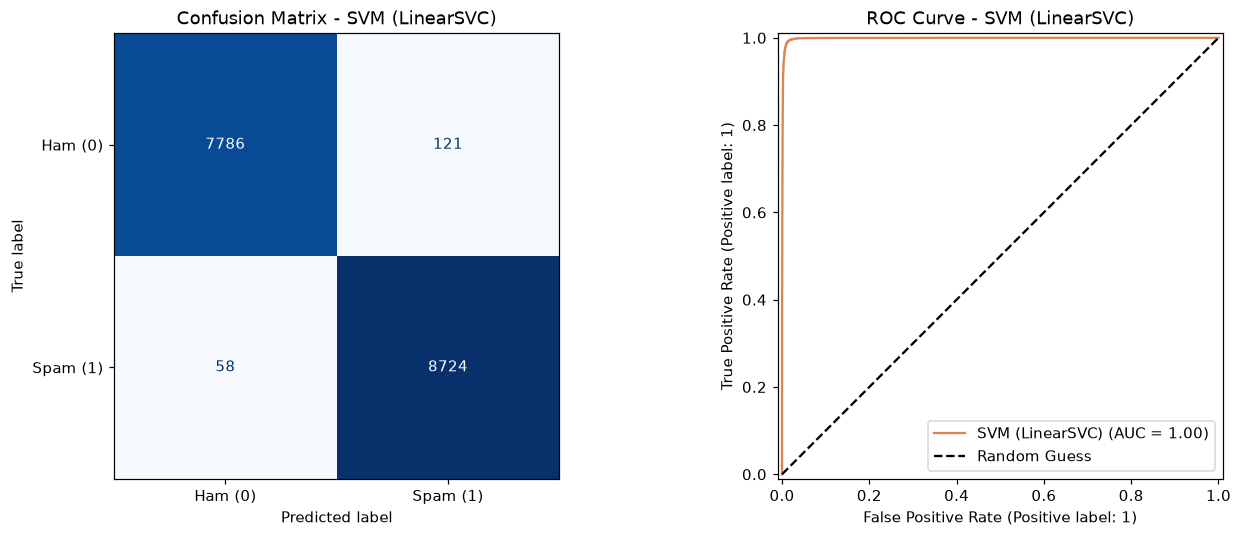

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham (0)', 'Spam (1)'])
disp.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion Matrix - SVM (LinearSVC)')

# 2. ROC Curve
RocCurveDisplay.from_predictions(y_test, y_score, name='SVM (LinearSVC)', ax=axes[1], curve_kwargs={'color': '#DD8452'})
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess')
axes[1].set_title('ROC Curve - SVM (LinearSVC)')
axes[1].legend()

plt.tight_layout()
plt.show()

6. Kiểm tra các từ đặc trưng & Phân tích lỗi

In [6]:
tfidf = best_model.named_steps['tfidf']
clf = best_model.named_steps['clf']
feature_names = np.array(tfidf.get_feature_names_out())
coefs = clf.coef_[0]

print("Top 10 từ/cụm từ đặc trưng cho SPAM:")
for idx in np.argsort(coefs)[-10:][::-1]:
    print(f"  {feature_names[idx]:<25} : +{coefs[idx]:.4f}")

print("\nTop 10 từ/cụm từ đặc trưng cho HAM:")
for idx in np.argsort(coefs)[:10]:
    print(f"  {feature_names[idx]:<25} : {coefs[idx]:.4f}")

# Xem 5 email dự đoán sai
error_df = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'pred_label': y_pred,
    'decision_score': y_score.round(4)
})
errors = error_df[error_df['true_label'] != error_df['pred_label']]
print(f"\nTổng số email đoán sai: {len(errors):,} / {len(y_test):,} ({len(errors)/len(y_test)*100:.2f}%)")
display(errors.head(5))

Top 10 từ/cụm từ đặc trưng cho SPAM:
  2004                      : +2.6980
  2005                      : +2.5823
  http                      : +2.3018
  freebsd                   : +1.7989
  ermx                      : +1.5752
  opinions                  : +1.5431
  meds                      : +1.4960
  hk                        : +1.4809
  remove                    : +1.4562
  amp                       : +1.4529

Top 10 từ/cụm từ đặc trưng cho HAM:
  enron                     : -5.6453
  wrote                     : -5.0640
  vince                     : -3.6392
  debian                    : -3.3658
  louise                    : -3.3424
  thanks                    : -3.2715
  perl                      : -3.1941
  samba                     : -2.9593
  attached                  : -2.5310
  713                       : -2.4383

Tổng số email đoán sai: 179 / 16,689 (1.07%)


                                                  text  ...  decision_score
51   stop making other people rich run your own bus...  ...         -0.1873
52   centroid terminates benzedrine boggled zebra v...  ...         -0.2190
106  i spoke with oscar wyatt this afternoon on cro...  ...          0.0611
200  ' for the record ' questions for the enside ne...  ...          0.1496
301  we want your used equipment keldata we buy use...  ...          0.9441

[5 rows x 4 columns]

7. Test, hiệu chỉnh xác suất và lưu lại mô hình

Cell 7a — Hiệu chỉnh xác suất (để lấy % độ tin cậy) và lưu file

In [7]:
import pickle

# Tạo pipeline SVM có hiệu chỉnh xác suất (CalibratedClassifierCV) từ tham số tốt nhất
best_C = grid_search.best_params_["C"]
best_loss = grid_search.best_params_["loss"]

calibrated_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))),
    ("clf", CalibratedClassifierCV(
        estimator=LinearSVC(C=best_C, loss=best_loss, dual=True, max_iter=2000, random_state=42),
        cv=3,
    )),
])

print("Đang hiệu chỉnh xác suất cho mô hình SVM...")
calibrated_svm_pipeline.fit(X_train, y_train)

# 1. Test thử dự đoán 2 email mẫu
def predict_email(text):
    prob = calibrated_svm_pipeline.predict_proba([text])[0][1]
    label = "SPAM" if prob >= 0.5 else "HAM"
    print(f"[{label}] (Xác suất Spam: {prob*100:.2f}%) -> {text[:60]}...")

print("\n--- DEMO DỰ ĐOÁN ---")
predict_email("Congratulations! You won a free $1000 gift card. Click here to claim your prize now!")
predict_email("Hi team, please find attached the meeting notes from yesterday's project sync.")

# 2. Lưu file mô hình dạng .pkl vào thư mục models/
model_path = models_dir / "svm_spam_pipeline.pkl"
with open(model_path, "wb") as f:
    pickle.dump(calibrated_svm_pipeline, f)

print(f"\nĐã lưu mô hình thành công tại: {model_path}")

Đang hiệu chỉnh xác suất cho mô hình SVM...

--- DEMO DỰ ĐOÁN ---
[SPAM] (Xác suất Spam: 95.36%) -> Congratulations! You won a free $1000 gift card. Click here ...
[HAM] (Xác suất Spam: 0.00%) -> Hi team, please find attached the meeting notes from yesterd...

Đã lưu mô hình thành công tại: D:\spam-email-classifier\models\svm_spam_pipeline.pkl


Cell 7b — Giao diện kiểm tra trực tiếp trên Colab

In [8]:
import re
import pickle

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets chưa được cài đặt - bỏ qua giao diện tương tác.")

if HAS_WIDGETS:
    try:
        model_to_test = calibrated_svm_pipeline
    except NameError:
        with open(models_dir / "svm_spam_pipeline.pkl", "rb") as f:
            model_to_test = pickle.load(f)

    text_input = widgets.Textarea(
        value="",
        placeholder="Dán hoặc nhập nội dung email tiếng Anh cần kiểm tra vào đây...",
        description="Nội dung:",
        layout=widgets.Layout(width="80%", height="150px"),
    )
    predict_btn = widgets.Button(description="Kiểm tra Email", button_style="primary", icon="search")
    clear_btn = widgets.Button(description="Xóa nội dung", button_style="", icon="trash")
    output_area = widgets.Output()

    def on_predict_clicked(b):
        with output_area:
            clear_output()
            raw_text = text_input.value.strip()
            if not raw_text:
                print("Vui lòng nhập nội dung email trước khi kiểm tra!")
                return
            cleaned = re.sub(r"\s+", " ", raw_text.lower()).strip()
            prob_spam = model_to_test.predict_proba([cleaned])[0][1]
            prob_ham = 1 - prob_spam
            if prob_spam >= 0.5:
                print(f"KẾT QUẢ: SPAM (Thư rác) - Độ tin cậy: {prob_spam * 100:.2f}%")
            else:
                print(f"KẾT QUẢ: HAM (Email bình thường) - Độ tin cậy: {prob_ham * 100:.2f}%")

    def on_clear_clicked(b):
        text_input.value = ""
        with output_area:
            clear_output()

    predict_btn.on_click(on_predict_clicked)
    clear_btn.on_click(on_clear_clicked)
    display(text_input, widgets.HBox([predict_btn, clear_btn]), output_area)

Textarea(value='', description='Nội dung:', layout=Layout(height='150px', width='80%'), placeholder='Dán hoặc nhập nội dung email tiếng Anh cần kiểm tra vào đây...') HBox(children=(Button(button_style='primary', description='Kiểm tra Email', icon='search', style=ButtonStyle()), Button(description='Xóa nội dung', icon='trash', style=ButtonStyle()))) Output()
